# Atividade 1: Replicação de artigo com AutoML
*   Nome: Ana Carolina Saggioratto Osello
*   Nº USP: 13683104





## Definições

In [22]:
# Clona o repositório e instala as dependências
!rm -rf /content/mlarrozprevisao
!git clone -q https://github.com/rgrion/mlarrozprevisao.git /content/mlarrozprevisao
!pip install -q -r /content/mlarrozprevisao/requirements.txt
!pip install -q "flaml[automl]==2.6.0"

In [23]:
# Compatibilidade com os nomes de arquivos
from pathlib import Path
import shutil
import os

dados_rice = Path("/content/mlarrozprevisao") / "[Tratados]Datasets_FAOSTAT_Rice_South_America"
dados_nasa = Path("/content/mlarrozprevisao") / "Datasets_NASA_FAOSTAT" / "dataset_NASA_FAOSTAT.csv"

for arquivo in dados_rice.glob("Rice_South_America_*.csv"):
    ano = arquivo.stem.split("_")[-1]
    shutil.copy(arquivo, f"/content/Rice_{ano}.csv")
    shutil.copy(arquivo, f"/content/Rice_South_America_{ano}.csv")

shutil.copy(dados_nasa, "/content/dataset_rice_clima.csv")
os.chdir("/content")

In [24]:
# Executa as células dos notebooks do github
import json
import time

def executar_github(caminho_notebook, indices):
    with open(caminho_notebook, "r", encoding="utf-8") as arquivo:
        notebook = json.load(arquivo)

    for indice in indices:
        celula = notebook["cells"][indice]
        if celula.get("cell_type") == "code":
            codigo = "".join(celula.get("source", []))
            exec(codigo, globals())

## Preparação e verificação dos dados

Os dados utilizados são os arquivos já tratados disponibilizados no repositório do artigo. Nesta etapa, os arquivos anuais são reunidos em um único DataFrame, são mantidas apenas as variáveis necessárias. Depois, a separação entre treino e teste e a modelagem são realizadas por país dentro de cada experimento.

A variável-alvo é Production (t).


In [25]:
import pandas as pd

# Colocar dados agrícolas em um DF
dados = []

for arquivo in sorted(dados_rice.glob("Rice_South_America_*.csv")):
    df_ano = pd.read_csv(arquivo)

    df_ano = df_ano[
        [
            "Area",
            "Year",
            "Area harvested (ha)",
            "Production (t)",
            "Yield (kg/ha)"
        ]
    ]

    df_ano = df_ano.dropna()
    df_ano = df_ano[df_ano["Area"] != "South America"]

    dados.append(df_ano)

df_total = pd.concat(dados, ignore_index=True)

# Dataset Dados Climáticos
df_clima = pd.read_csv(dados_nasa)

df_clima = df_clima.rename(columns={"Pais": "Area"})
df_clima = df_clima[df_clima["Area"] != "South America"]

print("Agrícolas:")
display(df_total.head())
print(df_total.shape)
print(df_total.columns)
print(df_total.isna().sum())

print("Clima:")
display(df_clima.head())
print(df_clima.shape)
print(df_clima.columns)
print(df_clima.isna().sum())


Agrícolas:


,Area,Year,Area harvested (ha),Production (t),Yield (kg/ha)
0,Argentina,2004,"169,178.00","1,060,083.00","6,266.10"
1,Bolivia (Plurinational State of),2004,"152,193.00","331,336.00","2,177.10"
2,Brazil,2004,"3,733,148.00","13,277,008.00","3,556.50"
3,Chile,2004,"24,900.00","119,265.00","4,789.80"
4,Colombia,2004,"519,736.00","2,496,720.00","4,803.80"


(243, 5)
Index(['Area', 'Year', 'Area harvested (ha)', 'Production (t)',
       'Yield (kg/ha)'],
      dtype='object')
Area                   0
Year                   0
Area harvested (ha)    0
Production (t)         0
Yield (kg/ha)          0
dtype: int64
Clima:


,Area,Year,Production (t),Area harvested (ha),Yield (kg/ha),Temp_Media_C,Precipitacao_mm
0,Argentina,2011,"1,748,075.00","257,445.00","6,790.10",16.85,22.72
1,Bolivia (Plurinational State of),2011,"428,007.00","178,273.00","2,400.90",25.68,26.22
2,Brazil,2011,"13,476,994.00","2,752,891.00","4,895.60",25.44,79.29
3,Chile,2011,"130,375.00","25,121.00","5,189.90",16.15,6.10
4,Colombia,2011,"2,009,945.00","507,709.00","3,958.90",25.20,115.21


(156, 7)
Index(['Area', 'Year', 'Production (t)', 'Area harvested (ha)',
       'Yield (kg/ha)', 'Temp_Media_C', 'Precipitacao_mm'],
      dtype='object')
Area                   0
Year                   0
Production (t)         0
Area harvested (ha)    0
Yield (kg/ha)          0
Temp_Media_C           0
Precipitacao_mm        0
dtype: int64


## AutoML com FLAML

Documentação: https://microsoft.github.io/FLAML/docs/Examples/AutoML-Regression/

Foram avaliados xgboost, rf, lgbm e enet. O MAPE é usado como métrica de seleção e também na avaliação final.

In [26]:
from flaml import AutoML


In [27]:
def treinar_flaml(X_train, y_train):
    automl = AutoML()

    automl_settings = {
        "time_budget": 10,
        "metric": "mape",
        "task": "regression",
        "estimator_list": ['lgbm', "xgboost", "rf", "enet"],
        "eval_method": "cv",
        "n_splits": 2,
        "max_iter": 35,
        "seed": 67,
    }

    automl.fit(
        X_train=X_train,
        y_train=y_train,
        **automl_settings
    )

    return automl


In [28]:
def automl_por_pais(
    df_total,
    anos_treino,
    anos_teste,
    features,
    nome_experimento
):
    resultados = []
    modelos = {}
    hiperparametros = {}

    inicio = time.perf_counter()

    df_treino = df_total[df_total["Year"].isin(anos_treino)]
    df_teste = df_total[df_total["Year"].isin(anos_teste)]

    for pais in sorted(df_treino["Area"].dropna().unique()):
        treino = df_treino[df_treino["Area"] == pais]
        teste = df_teste[df_teste["Area"] == pais]

        treino = treino[features + ["Production (t)"]].dropna()
        teste = teste[features + ["Production (t)"]].dropna()

        if len(treino) < 3 or teste.empty:
            continue

        X_train = treino[features]
        y_train = treino["Production (t)"]
        X_test = teste[features]
        y_test = teste["Production (t)"]

        automl = treinar_flaml(X_train, y_train)
        y_pred = automl.predict(X_test)

        modelos[pais] = automl.best_estimator
        hiperparametros[pais] = automl.best_config

        for ano, real, previsto in zip(teste["Year"], y_test, y_pred):
            erro = 100 * abs(previsto - real) / real

            resultados.append({
                "Area": pais,
                "Ano_Previsto": int(ano),
                "Production_Real": float(real),
                "Prod_AutoML": float(previsto),
                "Erro_%_Prod_AutoML": float(erro),
                "Modelo_AutoML": automl.best_estimator
            })

    tempo_total = time.perf_counter() - inicio
    df_resultados = pd.DataFrame(resultados)

    info = {
        "modelos": modelos,
        "hiperparametros": hiperparametros,
        "tempo_segundos": tempo_total
    }

    print(f"{nome_experimento}: {tempo_total:.2f} s")

    if not df_resultados.empty:
        mape = df_resultados["Erro_%_Prod_AutoML"].mean()
        print(f"MAPE AutoML: {mape:.2f}%")

    return df_resultados, info


## Experimento 5 anos

In [29]:
# Reprodução do notebook original
inicio_original = time.perf_counter()
executar_github(Path("/content/mlarrozprevisao") / r"Experimentos_Preliminares/Treinamento_Rice_South_America_2014_a_2018_5anos.ipynb", [1, 2, 3])
tempo_original_5 = time.perf_counter() - inicio_original
original_5 = df_resultado.copy()
print(f"Tempo: {tempo_original_5:.2f} s")


,Area,Ano_Previsto,Production_Real,Prod_LR,Prod_XGB,Prod_SVR,Erro_%_Prod_LR,Erro_%_Prod_XGB,Erro_%_Prod_SVR
0,Argentina,2019,"1,189,866.00","1,262,349.33","1,367,974.12","1,404,891.67",6.09,14.97,18.07
12,Argentina,2020,"1,222,910.00","1,289,697.48","1,367,974.12","1,404,906.98",5.46,11.86,14.88
24,Argentina,2021,"1,453,187.00","1,402,137.73","1,367,974.12","1,404,930.02",3.51,5.86,3.32
36,Argentina,2022,"1,222,426.00","1,322,513.35","1,367,974.12","1,404,959.07",8.19,11.91,14.93
48,Argentina,2023,"1,163,209.00","1,248,627.54","1,367,974.12","1,404,988.26",7.34,17.60,20.79
1,Bolivia (Plurinational State of),2019,"600,044.00","581,792.30","498,254.72","484,051.73",3.04,16.96,19.33
13,Bolivia (Plurinational State of),2020,"487,427.00","547,330.39","498,254.72","484,060.70",12.29,2.22,0.69
25,Bolivia (Plurinational State of),2021,"550,181.52","564,187.26","498,254.72","484,060.83",2.55,9.44,12.02
37,Bolivia (Plurinational State of),2022,"608,680.66","668,905.80","498,254.72","484,059.04",9.89,18.14,20.47
49,Bolivia (Plurinational State of),2023,"698,543.58","696,746.86","498,254.72","484,059.09",0.26,28.67,30.70


Tempo: 1.71 s


In [30]:
# AutoML 5 anos

automl_5, info_automl_5 = automl_por_pais(
    df_total,
    list(range(2014, 2019)),
    list(range(2019, 2024)),
    ["Year", "Area harvested (ha)"],
    "Janela de 5 anos"
)

display(automl_5.head())


[flaml.automl.logger: 08-31 02:37:28] {2375} INFO - task = regression
[flaml.automl.logger: 08-31 02:37:28] {2386} INFO - Evaluation method: cv
[flaml.automl.logger: 08-31 02:37:28] {2489} INFO - Minimizing error metric: mape
[flaml.automl.logger: 08-31 02:37:28] {2606} INFO - List of ML learners in AutoML Run: ['lgbm', 'xgboost', 'rf', 'enet']
[flaml.automl.logger: 08-31 02:37:28] {2911} INFO - iteration 0, current learner lgbm
[flaml.automl.logger: 08-31 02:37:28] {3046} INFO - Estimated sufficient time budget=220s. Estimated necessary time budget=0s.
[flaml.automl.logger: 08-31 02:37:28] {3097} INFO -  at 0.0s,	estimator lgbm's best error=7.1121e-02,	best estimator lgbm's best error=7.1121e-02
[flaml.automl.logger: 08-31 02:37:28] {2911} INFO - iteration 1, current learner lgbm
[flaml.automl.logger: 08-31 02:37:28] {3097} INFO -  at 0.1s,	estimator lgbm's best error=7.1121e-02,	best estimator lgbm's best error=7.1121e-02
[flaml.automl.logger: 08-31 02:37:28] {2911} INFO - iteration 

/usr/local/lib/python3.13/dist-packages/flaml/tune/space.py:345: RuntimeWarning: invalid value encountered in scalar divide
  config_norm[key] = np.log(value / domain.lower) / np.log(upper / domain.lower)
/usr/local/lib/python3.13/dist-packages/flaml/tune/searcher/flow2.py:239: RuntimeWarning: divide by zero encountered in scalar divide
  np.log(1.0 + 1.0 / self.best_config[key]) / np.log((domain.upper - 1) / domain.lower),
/usr/local/lib/python3.13/dist-packages/flaml/tune/space.py:345: RuntimeWarning: invalid value encountered in scalar divide
  config_norm[key] = np.log(value / domain.lower) / np.log(upper / domain.lower)
/usr/local/lib/python3.13/dist-packages/flaml/tune/searcher/flow2.py:239: RuntimeWarning: divide by zero encountered in scalar divide
  np.log(1.0 + 1.0 / self.best_config[key]) / np.log((domain.upper - 1) / domain.lower),
/usr/local/lib/python3.13/dist-packages/flaml/tune/space.py:345: RuntimeWarning: invalid value encountered in scalar divide
  config_norm[key] =

[flaml.automl.logger: 08-31 02:37:28] {3097} INFO -  at 0.1s,	estimator enet's best error=3.1047e-02,	best estimator enet's best error=3.1047e-02
[flaml.automl.logger: 08-31 02:37:28] {2911} INFO - iteration 4, current learner lgbm
[flaml.automl.logger: 08-31 02:37:28] {3097} INFO -  at 0.1s,	estimator lgbm's best error=7.1121e-02,	best estimator enet's best error=3.1047e-02
[flaml.automl.logger: 08-31 02:37:28] {2911} INFO - iteration 5, current learner enet
[flaml.automl.logger: 08-31 02:37:28] {3097} INFO -  at 0.1s,	estimator enet's best error=3.1047e-02,	best estimator enet's best error=3.1047e-02
[flaml.automl.logger: 08-31 02:37:28] {2911} INFO - iteration 6, current learner enet
[flaml.automl.logger: 08-31 02:37:28] {3097} INFO -  at 0.2s,	estimator enet's best error=2.6208e-02,	best estimator enet's best error=2.6208e-02
[flaml.automl.logger: 08-31 02:37:28] {2911} INFO - iteration 7, current learner lgbm
[flaml.automl.logger: 08-31 02:37:28] {3097} INFO -  at 0.2s,	estimator 

/usr/local/lib/python3.13/dist-packages/flaml/tune/space.py:345: RuntimeWarning: invalid value encountered in scalar divide
  config_norm[key] = np.log(value / domain.lower) / np.log(upper / domain.lower)
/usr/local/lib/python3.13/dist-packages/flaml/tune/space.py:345: RuntimeWarning: invalid value encountered in scalar divide
  config_norm[key] = np.log(value / domain.lower) / np.log(upper / domain.lower)
/usr/local/lib/python3.13/dist-packages/flaml/tune/space.py:345: RuntimeWarning: invalid value encountered in scalar divide
  config_norm[key] = np.log(value / domain.lower) / np.log(upper / domain.lower)


[flaml.automl.logger: 08-31 02:37:28] {3097} INFO -  at 0.2s,	estimator enet's best error=2.1865e-02,	best estimator enet's best error=2.1865e-02
[flaml.automl.logger: 08-31 02:37:28] {2911} INFO - iteration 10, current learner enet
[flaml.automl.logger: 08-31 02:37:28] {3097} INFO -  at 0.2s,	estimator enet's best error=2.1865e-02,	best estimator enet's best error=2.1865e-02
[flaml.automl.logger: 08-31 02:37:28] {2911} INFO - iteration 11, current learner enet
[flaml.automl.logger: 08-31 02:37:28] {3097} INFO -  at 0.3s,	estimator enet's best error=2.1865e-02,	best estimator enet's best error=2.1865e-02
[flaml.automl.logger: 08-31 02:37:28] {2911} INFO - iteration 12, current learner xgboost
[flaml.automl.logger: 08-31 02:37:28] {3097} INFO -  at 0.3s,	estimator xgboost's best error=6.5828e-02,	best estimator enet's best error=2.1865e-02
[flaml.automl.logger: 08-31 02:37:28] {2911} INFO - iteration 13, current learner xgboost


/usr/local/lib/python3.13/dist-packages/flaml/tune/space.py:345: RuntimeWarning: invalid value encountered in scalar divide
  config_norm[key] = np.log(value / domain.lower) / np.log(upper / domain.lower)
/usr/local/lib/python3.13/dist-packages/flaml/tune/searcher/flow2.py:239: RuntimeWarning: divide by zero encountered in scalar divide
  np.log(1.0 + 1.0 / self.best_config[key]) / np.log((domain.upper - 1) / domain.lower),
/usr/local/lib/python3.13/dist-packages/flaml/tune/space.py:345: RuntimeWarning: invalid value encountered in scalar divide
  config_norm[key] = np.log(value / domain.lower) / np.log(upper / domain.lower)
/usr/local/lib/python3.13/dist-packages/flaml/tune/searcher/flow2.py:239: RuntimeWarning: divide by zero encountered in scalar divide
  np.log(1.0 + 1.0 / self.best_config[key]) / np.log((domain.upper - 1) / domain.lower),


... (249 outputs left out)

/usr/local/lib/python3.13/dist-packages/flaml/tune/space.py:345: RuntimeWarning: invalid value encountered in scalar divide
  config_norm[key] = np.log(value / domain.lower) / np.log(upper / domain.lower)
/usr/local/lib/python3.13/dist-packages/flaml/tune/space.py:345: RuntimeWarning: invalid value encountered in scalar divide
  config_norm[key] = np.log(value / domain.lower) / np.log(upper / domain.lower)
/usr/local/lib/python3.13/dist-packages/flaml/tune/space.py:345: RuntimeWarning: invalid value encountered in scalar divide
  config_norm[key] = np.log(value / domain.lower) / np.log(upper / domain.lower)
/usr/local/lib/python3.13/dist-packages/flaml/tune/searcher/flow2.py:239: RuntimeWarning: divide by zero encountered in scalar divide
  np.log(1.0 + 1.0 / self.best_config[key]) / np.log((domain.upper - 1) / domain.lower),


[flaml.automl.logger: 08-31 02:37:58] {3097} INFO -  at 1.8s,	estimator enet's best error=1.3420e-01,	best estimator enet's best error=1.3420e-01
[flaml.automl.logger: 08-31 02:37:58] {2911} INFO - iteration 34, current learner lgbm
[flaml.automl.logger: 08-31 02:37:58] {3097} INFO -  at 1.8s,	estimator lgbm's best error=3.6717e-01,	best estimator enet's best error=1.3420e-01
[flaml.automl.logger: 08-31 02:37:58] {3359} INFO - retrain enet for 0.0s
[flaml.automl.logger: 08-31 02:37:58] {3362} INFO - retrained model: ElasticNet(alpha=np.float64(0.019184827762924662),
           l1_ratio=np.float64(0.5276177785810326), random_state=10242048,
           selection=np.str_('random'))
[flaml.automl.logger: 08-31 02:37:58] {2636} INFO - fit succeeded
[flaml.automl.logger: 08-31 02:37:58] {2637} INFO - Time taken to find the best model: 1.4547486305236816
Janela de 5 anos: 30.36 s
MAPE AutoML: 13.24%


/usr/local/lib/python3.13/dist-packages/flaml/tune/space.py:345: RuntimeWarning: invalid value encountered in scalar divide
  config_norm[key] = np.log(value / domain.lower) / np.log(upper / domain.lower)


,Area,Ano_Previsto,Production_Real,Prod_AutoML,Erro_%_Prod_AutoML,Modelo_AutoML
0,Argentina,2019,"1,189,866.00","1,258,175.12",5.74,enet
1,Argentina,2020,"1,222,910.00","1,273,015.94",4.10,enet
2,Argentina,2021,"1,453,187.00","1,362,358.10",6.25,enet
3,Argentina,2022,"1,222,426.00","1,283,540.44",5.00,enet
4,Argentina,2023,"1,163,209.00","1,209,747.12",4.00,enet


## Experimento 10 anos

In [31]:
# Reprodução do notebook original
inicio_original = time.perf_counter()
executar_github(Path("/content/mlarrozprevisao") / r"Experimentos_Preliminares/Treinamento_Rice_South_America_2009_a_2018_5anos.ipynb", [1, 2, 3])
tempo_original_10 = time.perf_counter() - inicio_original
original_10 = df_resultado.copy()
print(f"Tempo: {tempo_original_10:.2f} s")


,Area,Ano_Previsto,Production_Real,Prod_LR,Prod_XGB,Prod_SVR,Erro_%_Prod_LR,Erro_%_Prod_XGB,Erro_%_Prod_SVR
0,Argentina,2019,"1,189,866.00","1,242,513.78","1,367,969.88","1,481,356.31",4.42,14.97,24.50
12,Argentina,2020,"1,222,910.00","1,263,232.83","1,367,969.88","1,481,364.50",3.30,11.86,21.13
24,Argentina,2021,"1,453,187.00","1,370,694.47","1,367,969.88","1,481,396.81",5.68,5.86,1.94
36,Argentina,2022,"1,222,426.00","1,282,366.09","1,367,969.88","1,481,385.44",4.90,11.91,21.18
48,Argentina,2023,"1,163,209.00","1,199,887.61","1,367,969.88","1,481,402.54",3.15,17.60,27.35
1,Bolivia (Plurinational State of),2019,"600,044.00","515,743.37","515,305.84","458,817.41",14.05,14.12,23.54
13,Bolivia (Plurinational State of),2020,"487,427.00","524,497.74","515,305.84","458,868.66",7.61,5.72,5.86
25,Bolivia (Plurinational State of),2021,"550,181.52","533,947.12","515,305.84","458,859.46",2.95,6.34,16.60
37,Bolivia (Plurinational State of),2022,"608,680.66","544,586.43","515,305.84","458,764.06",10.53,15.34,24.63
49,Bolivia (Plurinational State of),2023,"698,543.58","554,184.58","515,305.84","458,751.07",20.67,26.23,34.33


Tempo: 2.78 s


In [32]:
# AutoML 10 anos

automl_10, info_automl_10 = automl_por_pais(
    df_total,
    list(range(2009, 2019)),
    list(range(2019, 2024)),
    ["Year", "Area harvested (ha)"],
    "10 anos"
)

display(automl_10.head())


[flaml.automl.logger: 08-31 02:38:01] {2375} INFO - task = regression
[flaml.automl.logger: 08-31 02:38:01] {2386} INFO - Evaluation method: cv
[flaml.automl.logger: 08-31 02:38:01] {2489} INFO - Minimizing error metric: mape
[flaml.automl.logger: 08-31 02:38:01] {2606} INFO - List of ML learners in AutoML Run: ['lgbm', 'xgboost', 'rf', 'enet']
[flaml.automl.logger: 08-31 02:38:01] {2911} INFO - iteration 0, current learner lgbm
[flaml.automl.logger: 08-31 02:38:01] {3046} INFO - Estimated sufficient time budget=164s. Estimated necessary time budget=0s.
[flaml.automl.logger: 08-31 02:38:01] {3097} INFO -  at 0.0s,	estimator lgbm's best error=9.4831e-02,	best estimator lgbm's best error=9.4831e-02
[flaml.automl.logger: 08-31 02:38:01] {2911} INFO - iteration 1, current learner lgbm
[flaml.automl.logger: 08-31 02:38:01] {3097} INFO -  at 0.0s,	estimator lgbm's best error=9.4831e-02,	best estimator lgbm's best error=9.4831e-02
[flaml.automl.logger: 08-31 02:38:01] {2911} INFO - iteration 

INFO:flaml.tune.searcher.blendsearch:No low-cost partial config given to the search algorithm. For cost-frugal search, consider providing low-cost values for cost-related hps via 'low_cost_partial_config'. More info can be found at https://microsoft.github.io/FLAML/docs/FAQ#about-low_cost_partial_config-in-tune


[flaml.automl.logger: 08-31 02:38:01] {3097} INFO -  at 0.1s,	estimator enet's best error=3.8359e-02,	best estimator enet's best error=3.8359e-02
[flaml.automl.logger: 08-31 02:38:01] {2911} INFO - iteration 4, current learner lgbm
[flaml.automl.logger: 08-31 02:38:01] {3097} INFO -  at 0.1s,	estimator lgbm's best error=9.4831e-02,	best estimator enet's best error=3.8359e-02
[flaml.automl.logger: 08-31 02:38:01] {2911} INFO - iteration 5, current learner enet
[flaml.automl.logger: 08-31 02:38:01] {3097} INFO -  at 0.1s,	estimator enet's best error=3.8359e-02,	best estimator enet's best error=3.8359e-02
[flaml.automl.logger: 08-31 02:38:01] {2911} INFO - iteration 6, current learner lgbm
[flaml.automl.logger: 08-31 02:38:01] {3097} INFO -  at 0.1s,	estimator lgbm's best error=9.4831e-02,	best estimator enet's best error=3.8359e-02
[flaml.automl.logger: 08-31 02:38:01] {2911} INFO - iteration 7, current learner lgbm
[flaml.automl.logger: 08-31 02:38:01] {3097} INFO -  at 0.2s,	estimator 

/usr/local/lib/python3.13/dist-packages/flaml/tune/space.py:345: RuntimeWarning: invalid value encountered in scalar divide
  config_norm[key] = np.log(value / domain.lower) / np.log(upper / domain.lower)
/usr/local/lib/python3.13/dist-packages/flaml/tune/searcher/flow2.py:239: RuntimeWarning: divide by zero encountered in scalar divide
  np.log(1.0 + 1.0 / self.best_config[key]) / np.log((domain.upper - 1) / domain.lower),
/usr/local/lib/python3.13/dist-packages/flaml/tune/space.py:345: RuntimeWarning: invalid value encountered in scalar divide
  config_norm[key] = np.log(value / domain.lower) / np.log(upper / domain.lower)
/usr/local/lib/python3.13/dist-packages/flaml/tune/searcher/flow2.py:239: RuntimeWarning: divide by zero encountered in scalar divide
  np.log(1.0 + 1.0 / self.best_config[key]) / np.log((domain.upper - 1) / domain.lower),
/usr/local/lib/python3.13/dist-packages/flaml/tune/space.py:345: RuntimeWarning: invalid value encountered in scalar divide
  config_norm[key] =

[flaml.automl.logger: 08-31 02:38:01] {3097} INFO -  at 0.5s,	estimator rf's best error=5.8157e-02,	best estimator enet's best error=3.6562e-02
[flaml.automl.logger: 08-31 02:38:01] {2911} INFO - iteration 20, current learner xgboost
[flaml.automl.logger: 08-31 02:38:01] {3097} INFO -  at 0.5s,	estimator xgboost's best error=9.2935e-02,	best estimator enet's best error=3.6562e-02
[flaml.automl.logger: 08-31 02:38:01] {2911} INFO - iteration 21, current learner enet
[flaml.automl.logger: 08-31 02:38:01] {3097} INFO -  at 0.6s,	estimator enet's best error=3.6562e-02,	best estimator enet's best error=3.6562e-02
[flaml.automl.logger: 08-31 02:38:01] {2911} INFO - iteration 22, current learner lgbm
[flaml.automl.logger: 08-31 02:38:01] {3097} INFO -  at 0.6s,	estimator lgbm's best error=9.4831e-02,	best estimator enet's best error=3.6562e-02
[flaml.automl.logger: 08-31 02:38:01] {2911} INFO - iteration 23, current learner xgboost
[flaml.automl.logger: 08-31 02:38:02] {3097} INFO -  at 0.6s,

/usr/local/lib/python3.13/dist-packages/flaml/tune/space.py:345: RuntimeWarning: invalid value encountered in scalar divide
  config_norm[key] = np.log(value / domain.lower) / np.log(upper / domain.lower)


... (84 outputs left out)

[flaml.automl.logger: 08-31 02:38:13] {3097} INFO -  at 0.7s,	estimator xgboost's best error=2.4715e-01,	best estimator enet's best error=2.1252e-01
[flaml.automl.logger: 08-31 02:38:13] {2911} INFO - iteration 24, current learner enet
[flaml.automl.logger: 08-31 02:38:14] {3097} INFO -  at 0.7s,	estimator enet's best error=2.1252e-01,	best estimator enet's best error=2.1252e-01
[flaml.automl.logger: 08-31 02:38:14] {2911} INFO - iteration 25, current learner enet
[flaml.automl.logger: 08-31 02:38:14] {3097} INFO -  at 0.7s,	estimator enet's best error=2.1252e-01,	best estimator enet's best error=2.1252e-01
[flaml.automl.logger: 08-31 02:38:14] {2911} INFO - iteration 26, current learner xgboost
[flaml.automl.logger: 08-31 02:38:14] {3097} INFO -  at 0.7s,	estimator xgboost's best error=2.4715e-01,	best estimator enet's best error=2.1252e-01
[flaml.automl.logger: 08-31 02:38:14] {2911} INFO - iteration 27, current learner rf
[flaml.automl.logger: 08-31 02:38:14] {3097} INFO -  at 0.8s,

/usr/local/lib/python3.13/dist-packages/flaml/tune/space.py:345: RuntimeWarning: invalid value encountered in scalar divide
  config_norm[key] = np.log(value / domain.lower) / np.log(upper / domain.lower)


[flaml.automl.logger: 08-31 02:38:14] {3097} INFO -  at 0.9s,	estimator enet's best error=2.0798e-01,	best estimator enet's best error=2.0798e-01
[flaml.automl.logger: 08-31 02:38:14] {2911} INFO - iteration 34, current learner lgbm
[flaml.automl.logger: 08-31 02:38:14] {3097} INFO -  at 1.0s,	estimator lgbm's best error=4.0571e-01,	best estimator enet's best error=2.0798e-01
[flaml.automl.logger: 08-31 02:38:14] {3359} INFO - retrain enet for 0.0s
[flaml.automl.logger: 08-31 02:38:14] {3362} INFO - retrained model: ElasticNet(l1_ratio=np.float64(0.38622283906962585), random_state=10242048,
           selection=np.str_('random'))
[flaml.automl.logger: 08-31 02:38:14] {2636} INFO - fit succeeded
[flaml.automl.logger: 08-31 02:38:14] {2637} INFO - Time taken to find the best model: 0.8655874729156494
10 anos: 12.90 s
MAPE AutoML: 12.61%


,Area,Ano_Previsto,Production_Real,Prod_AutoML,Erro_%_Prod_AutoML,Modelo_AutoML
0,Argentina,2019,"1,189,866.00","1,240,621.43",4.27,enet
1,Argentina,2020,"1,222,910.00","1,260,847.74",3.10,enet
2,Argentina,2021,"1,453,187.00","1,367,608.79",5.89,enet
3,Argentina,2022,"1,222,426.00","1,279,048.97",4.63,enet
4,Argentina,2023,"1,163,209.00","1,196,325.03",2.85,enet


## Experimento 15 anos

In [33]:
# Reprodução do notebook original
inicio_original = time.perf_counter()
executar_github(Path("/content/mlarrozprevisao") / r"Experimentos_Preliminares/Treinamento_Rice_South_America_2004_a_2018_5anos.ipynb", [1, 2, 3])
tempo_original_15 = time.perf_counter() - inicio_original
original_15 = df_resultado.copy()
print(f"Tempo: {tempo_original_15:.2f} s")


,Area,Ano_Previsto,Production_Real,Prod_LR,Prod_XGB,Prod_SVR,Erro_%_Prod_LR,Erro_%_Prod_XGB,Erro_%_Prod_SVR
0,Argentina,2019,"1,189,866.00","1,250,095.35","1,367,968.38","1,334,387.32",5.06,14.97,12.15
12,Argentina,2020,"1,222,910.00","1,267,693.12","1,367,968.38","1,334,405.50",3.66,11.86,9.12
24,Argentina,2021,"1,453,187.00","1,367,016.77","1,367,968.38","1,334,460.98",5.93,5.86,8.17
36,Argentina,2022,"1,222,426.00","1,281,873.80","1,367,968.38","1,334,415.62",4.86,11.91,9.16
48,Argentina,2023,"1,163,209.00","1,202,242.39","1,367,968.38","1,334,376.79",3.36,17.60,14.72
1,Bolivia (Plurinational State of),2019,"600,044.00","540,385.43","499,622.69","442,934.26",9.94,16.74,26.18
13,Bolivia (Plurinational State of),2020,"487,427.00","530,548.57","499,622.69","442,982.71",8.85,2.50,9.12
25,Bolivia (Plurinational State of),2021,"550,181.52","543,576.71","499,622.69","442,978.93",1.20,9.19,19.48
37,Bolivia (Plurinational State of),2022,"608,680.66","595,751.46","499,536.75","442,880.62",2.12,17.93,27.24
49,Bolivia (Plurinational State of),2023,"698,543.58","613,673.59","499,536.75","442,868.11",12.15,28.49,36.60


Tempo: 1.46 s


In [34]:
# AutoML 15 anos

automl_15, info_automl_15 = automl_por_pais(
    df_total,
    list(range(2004, 2019)),
    list(range(2019, 2024)),
    ["Year", "Area harvested (ha)"],
    "15 anos"
)

display(automl_15.head())


[flaml.automl.logger: 08-31 02:38:15] {2375} INFO - task = regression
[flaml.automl.logger: 08-31 02:38:15] {2386} INFO - Evaluation method: cv
[flaml.automl.logger: 08-31 02:38:15] {2489} INFO - Minimizing error metric: mape
[flaml.automl.logger: 08-31 02:38:15] {2606} INFO - List of ML learners in AutoML Run: ['lgbm', 'xgboost', 'rf', 'enet']
[flaml.automl.logger: 08-31 02:38:15] {2911} INFO - iteration 0, current learner lgbm
[flaml.automl.logger: 08-31 02:38:15] {3046} INFO - Estimated sufficient time budget=123s. Estimated necessary time budget=0s.
[flaml.automl.logger: 08-31 02:38:15] {3097} INFO -  at 0.0s,	estimator lgbm's best error=1.4579e-01,	best estimator lgbm's best error=1.4579e-01
[flaml.automl.logger: 08-31 02:38:15] {2911} INFO - iteration 1, current learner lgbm
[flaml.automl.logger: 08-31 02:38:15] {3097} INFO -  at 0.0s,	estimator lgbm's best error=1.4579e-01,	best estimator lgbm's best error=1.4579e-01
[flaml.automl.logger: 08-31 02:38:15] {2911} INFO - iteration 

INFO:flaml.tune.searcher.blendsearch:No low-cost partial config given to the search algorithm. For cost-frugal search, consider providing low-cost values for cost-related hps via 'low_cost_partial_config'. More info can be found at https://microsoft.github.io/FLAML/docs/FAQ#about-low_cost_partial_config-in-tune


[flaml.automl.logger: 08-31 02:38:15] {3097} INFO -  at 0.1s,	estimator enet's best error=4.7338e-02,	best estimator enet's best error=4.7338e-02
[flaml.automl.logger: 08-31 02:38:15] {2911} INFO - iteration 3, current learner enet
[flaml.automl.logger: 08-31 02:38:15] {3097} INFO -  at 0.1s,	estimator enet's best error=4.7337e-02,	best estimator enet's best error=4.7337e-02
[flaml.automl.logger: 08-31 02:38:15] {2911} INFO - iteration 4, current learner lgbm
[flaml.automl.logger: 08-31 02:38:15] {3097} INFO -  at 0.1s,	estimator lgbm's best error=1.4579e-01,	best estimator enet's best error=4.7337e-02
[flaml.automl.logger: 08-31 02:38:15] {2911} INFO - iteration 5, current learner enet
[flaml.automl.logger: 08-31 02:38:15] {3097} INFO -  at 0.1s,	estimator enet's best error=4.7337e-02,	best estimator enet's best error=4.7337e-02
[flaml.automl.logger: 08-31 02:38:15] {2911} INFO - iteration 6, current learner lgbm
[flaml.automl.logger: 08-31 02:38:15] {3097} INFO -  at 0.1s,	estimator 

INFO:flaml.tune.searcher.blendsearch:No low-cost partial config given to the search algorithm. For cost-frugal search, consider providing low-cost values for cost-related hps via 'low_cost_partial_config'. More info can be found at https://microsoft.github.io/FLAML/docs/FAQ#about-low_cost_partial_config-in-tune


[flaml.automl.logger: 08-31 02:38:17] {3097} INFO -  at 0.1s,	estimator enet's best error=1.5009e-01,	best estimator enet's best error=1.5009e-01
[flaml.automl.logger: 08-31 02:38:17] {2911} INFO - iteration 4, current learner lgbm
[flaml.automl.logger: 08-31 02:38:17] {3097} INFO -  at 0.1s,	estimator lgbm's best error=1.7111e-01,	best estimator enet's best error=1.5009e-01
[flaml.automl.logger: 08-31 02:38:17] {2911} INFO - iteration 5, current learner enet
[flaml.automl.logger: 08-31 02:38:17] {3097} INFO -  at 0.1s,	estimator enet's best error=1.5009e-01,	best estimator enet's best error=1.5009e-01
[flaml.automl.logger: 08-31 02:38:17] {2911} INFO - iteration 6, current learner lgbm
[flaml.automl.logger: 08-31 02:38:17] {3097} INFO -  at 0.1s,	estimator lgbm's best error=1.7111e-01,	best estimator enet's best error=1.5009e-01
[flaml.automl.logger: 08-31 02:38:17] {2911} INFO - iteration 7, current learner lgbm
[flaml.automl.logger: 08-31 02:38:17] {3097} INFO -  at 0.1s,	estimator 

INFO:flaml.tune.searcher.blendsearch:No low-cost partial config given to the search algorithm. For cost-frugal search, consider providing low-cost values for cost-related hps via 'low_cost_partial_config'. More info can be found at https://microsoft.github.io/FLAML/docs/FAQ#about-low_cost_partial_config-in-tune


... (16 outputs left out)

[flaml.automl.logger: 08-31 02:38:25] {3097} INFO -  at 0.1s,	estimator enet's best error=8.4495e-02,	best estimator lgbm's best error=7.6505e-02
[flaml.automl.logger: 08-31 02:38:25] {2911} INFO - iteration 5, current learner enet
[flaml.automl.logger: 08-31 02:38:25] {3097} INFO -  at 0.1s,	estimator enet's best error=8.4495e-02,	best estimator lgbm's best error=7.6505e-02
[flaml.automl.logger: 08-31 02:38:25] {2911} INFO - iteration 6, current learner lgbm
[flaml.automl.logger: 08-31 02:38:25] {3097} INFO -  at 0.2s,	estimator lgbm's best error=7.6505e-02,	best estimator lgbm's best error=7.6505e-02
[flaml.automl.logger: 08-31 02:38:25] {2911} INFO - iteration 7, current learner lgbm
[flaml.automl.logger: 08-31 02:38:25] {3097} INFO -  at 0.2s,	estimator lgbm's best error=7.6505e-02,	best estimator lgbm's best error=7.6505e-02
[flaml.automl.logger: 08-31 02:38:25] {2911} INFO - iteration 8, current learner enet
[flaml.automl.logger: 08-31 02:38:25] {3097} INFO -  at 0.2s,	estimator 

INFO:flaml.tune.searcher.blendsearch:No low-cost partial config given to the search algorithm. For cost-frugal search, consider providing low-cost values for cost-related hps via 'low_cost_partial_config'. More info can be found at https://microsoft.github.io/FLAML/docs/FAQ#about-low_cost_partial_config-in-tune


[flaml.automl.logger: 08-31 02:38:26] {3097} INFO -  at 0.1s,	estimator enet's best error=1.0469e-01,	best estimator enet's best error=1.0469e-01
[flaml.automl.logger: 08-31 02:38:26] {2911} INFO - iteration 3, current learner enet
[flaml.automl.logger: 08-31 02:38:26] {3097} INFO -  at 0.1s,	estimator enet's best error=1.0469e-01,	best estimator enet's best error=1.0469e-01
[flaml.automl.logger: 08-31 02:38:26] {2911} INFO - iteration 4, current learner lgbm
[flaml.automl.logger: 08-31 02:38:26] {3097} INFO -  at 0.1s,	estimator lgbm's best error=2.5806e-01,	best estimator enet's best error=1.0469e-01
[flaml.automl.logger: 08-31 02:38:26] {2911} INFO - iteration 5, current learner enet
[flaml.automl.logger: 08-31 02:38:26] {3097} INFO -  at 0.1s,	estimator enet's best error=1.0464e-01,	best estimator enet's best error=1.0464e-01
[flaml.automl.logger: 08-31 02:38:26] {2911} INFO - iteration 6, current learner xgboost
[flaml.automl.logger: 08-31 02:38:26] {3097} INFO -  at 0.1s,	estimat

,Area,Ano_Previsto,Production_Real,Prod_AutoML,Erro_%_Prod_AutoML,Modelo_AutoML
0,Argentina,2019,"1,189,866.00","1,260,636.13",5.95,rf
1,Argentina,2020,"1,222,910.00","1,260,636.13",3.08,rf
2,Argentina,2021,"1,453,187.00","1,334,579.97",8.16,rf
3,Argentina,2022,"1,222,426.00","1,260,636.13",3.13,rf
4,Argentina,2023,"1,163,209.00","1,260,636.13",8.38,rf


## Experimento Final

In [35]:
# Reprodução do notebook original
inicio_original = time.perf_counter()
executar_github(Path("/content/mlarrozprevisao") / r"Treinamento_Rice_South_America_2011_a_2020_3anos.ipynb", [1, 2, 3])
tempo_original_final = time.perf_counter() - inicio_original
original_final = df_resultado.copy()
print(f"Tempo: {tempo_original_final:.2f} s")


,Area,Ano_Previsto,Production_Real,Prod_LR,Prod_XGB,Prod_SVR,Erro_%_Prod_LR,Erro_%_Prod_XGB,Erro_%_Prod_SVR
0,Argentina,2021,"1,453,187.00","1,306,276.96","1,222,927.12","1,481,276.85",10.11,15.85,1.93
12,Argentina,2022,"1,222,426.00","1,214,021.80","1,222,927.12","1,481,253.21",0.69,0.04,21.17
24,Argentina,2023,"1,163,209.00","1,127,025.93","1,215,584.25","1,481,268.28",3.11,4.50,27.34
1,Bolivia (Plurinational State of),2021,"550,181.52","547,290.40","487,426.91","481,449.25",0.53,11.41,12.49
13,Bolivia (Plurinational State of),2022,"608,680.66","602,519.49","559,388.50","481,385.56",1.01,8.10,20.91
25,Bolivia (Plurinational State of),2023,"698,543.58","620,482.47","559,388.50","481,356.16",11.17,19.92,31.09
2,Brazil,2021,"11,660,605.00","12,112,078.12","11,091,107.00","11,795,409.67",3.87,4.88,1.16
14,Brazil,2022,"10,776,268.00","12,274,277.40","11,091,107.00","11,795,402.29",13.90,2.92,9.46
26,Brazil,2023,"10,285,663.00","11,853,745.16","11,091,107.00","11,795,396.15",15.25,7.83,14.68
3,Chile,2021,"146,085.10","158,364.16","138,562.94","156,866.20",8.41,5.15,7.38


Tempo: 0.90 s


In [36]:
# AutoML experimento Final

automl_final, info_automl_final = automl_por_pais(
    df_total,
    list(range(2011, 2021)),
    list(range(2021, 2024)),
    ["Year", "Area harvested (ha)"],
    "Experimento Final"
)

display(automl_final.head())


[flaml.automl.logger: 08-31 02:38:29] {2375} INFO - task = regression
[flaml.automl.logger: 08-31 02:38:29] {2386} INFO - Evaluation method: cv
[flaml.automl.logger: 08-31 02:38:29] {2489} INFO - Minimizing error metric: mape
[flaml.automl.logger: 08-31 02:38:29] {2606} INFO - List of ML learners in AutoML Run: ['lgbm', 'xgboost', 'rf', 'enet']
[flaml.automl.logger: 08-31 02:38:29] {2911} INFO - iteration 0, current learner lgbm
[flaml.automl.logger: 08-31 02:38:29] {3046} INFO - Estimated sufficient time budget=126s. Estimated necessary time budget=0s.
[flaml.automl.logger: 08-31 02:38:29] {3097} INFO -  at 0.0s,	estimator lgbm's best error=1.1949e-01,	best estimator lgbm's best error=1.1949e-01
[flaml.automl.logger: 08-31 02:38:29] {2911} INFO - iteration 1, current learner lgbm
[flaml.automl.logger: 08-31 02:38:29] {3097} INFO -  at 0.0s,	estimator lgbm's best error=1.1949e-01,	best estimator lgbm's best error=1.1949e-01
[flaml.automl.logger: 08-31 02:38:29] {2911} INFO - iteration 

INFO:flaml.tune.searcher.blendsearch:No low-cost partial config given to the search algorithm. For cost-frugal search, consider providing low-cost values for cost-related hps via 'low_cost_partial_config'. More info can be found at https://microsoft.github.io/FLAML/docs/FAQ#about-low_cost_partial_config-in-tune


[flaml.automl.logger: 08-31 02:38:29] {3097} INFO -  at 0.1s,	estimator enet's best error=1.9158e-02,	best estimator enet's best error=1.9158e-02
[flaml.automl.logger: 08-31 02:38:29] {2911} INFO - iteration 3, current learner enet
[flaml.automl.logger: 08-31 02:38:29] {3097} INFO -  at 0.1s,	estimator enet's best error=1.9158e-02,	best estimator enet's best error=1.9158e-02
[flaml.automl.logger: 08-31 02:38:29] {2911} INFO - iteration 4, current learner lgbm
[flaml.automl.logger: 08-31 02:38:29] {3097} INFO -  at 0.1s,	estimator lgbm's best error=1.1949e-01,	best estimator enet's best error=1.9158e-02
[flaml.automl.logger: 08-31 02:38:29] {2911} INFO - iteration 5, current learner enet
[flaml.automl.logger: 08-31 02:38:29] {3097} INFO -  at 0.1s,	estimator enet's best error=1.8960e-02,	best estimator enet's best error=1.8960e-02
[flaml.automl.logger: 08-31 02:38:29] {2911} INFO - iteration 6, current learner xgboost
[flaml.automl.logger: 08-31 02:38:29] {3097} INFO -  at 0.1s,	estimat

/usr/local/lib/python3.13/dist-packages/flaml/tune/space.py:345: RuntimeWarning: invalid value encountered in scalar divide
  config_norm[key] = np.log(value / domain.lower) / np.log(upper / domain.lower)
/usr/local/lib/python3.13/dist-packages/flaml/tune/searcher/flow2.py:239: RuntimeWarning: divide by zero encountered in scalar divide
  np.log(1.0 + 1.0 / self.best_config[key]) / np.log((domain.upper - 1) / domain.lower),
/usr/local/lib/python3.13/dist-packages/flaml/tune/space.py:345: RuntimeWarning: invalid value encountered in scalar divide
  config_norm[key] = np.log(value / domain.lower) / np.log(upper / domain.lower)
/usr/local/lib/python3.13/dist-packages/flaml/tune/searcher/flow2.py:239: RuntimeWarning: divide by zero encountered in scalar divide
  np.log(1.0 + 1.0 / self.best_config[key]) / np.log((domain.upper - 1) / domain.lower),
/usr/local/lib/python3.13/dist-packages/flaml/tune/space.py:345: RuntimeWarning: invalid value encountered in scalar divide
  config_norm[key] =

[flaml.automl.logger: 08-31 02:38:29] {3097} INFO -  at 0.5s,	estimator rf's best error=5.3514e-02,	best estimator enet's best error=1.8654e-02
[flaml.automl.logger: 08-31 02:38:29] {2911} INFO - iteration 21, current learner enet
[flaml.automl.logger: 08-31 02:38:29] {3097} INFO -  at 0.5s,	estimator enet's best error=1.8654e-02,	best estimator enet's best error=1.8654e-02
[flaml.automl.logger: 08-31 02:38:29] {2911} INFO - iteration 22, current learner lgbm
[flaml.automl.logger: 08-31 02:38:29] {3097} INFO -  at 0.5s,	estimator lgbm's best error=1.1949e-01,	best estimator enet's best error=1.8654e-02
[flaml.automl.logger: 08-31 02:38:29] {2911} INFO - iteration 23, current learner lgbm
[flaml.automl.logger: 08-31 02:38:29] {3097} INFO -  at 0.6s,	estimator lgbm's best error=1.1949e-01,	best estimator enet's best error=1.8654e-02
[flaml.automl.logger: 08-31 02:38:29] {2911} INFO - iteration 24, current learner enet
[flaml.automl.logger: 08-31 02:38:29] {3097} INFO -  at 0.6s,	estimato

/usr/local/lib/python3.13/dist-packages/flaml/tune/space.py:345: RuntimeWarning: invalid value encountered in scalar divide
  config_norm[key] = np.log(value / domain.lower) / np.log(upper / domain.lower)


... (68 outputs left out)

[flaml.automl.logger: 08-31 02:38:40] {3097} INFO -  at 0.6s,	estimator rf's best error=1.4382e-01,	best estimator enet's best error=1.2039e-01
[flaml.automl.logger: 08-31 02:38:40] {2911} INFO - iteration 21, current learner rf
[flaml.automl.logger: 08-31 02:38:41] {3097} INFO -  at 0.7s,	estimator rf's best error=1.3784e-01,	best estimator enet's best error=1.2039e-01
[flaml.automl.logger: 08-31 02:38:41] {2911} INFO - iteration 22, current learner lgbm
[flaml.automl.logger: 08-31 02:38:41] {3097} INFO -  at 0.7s,	estimator lgbm's best error=3.5129e-01,	best estimator enet's best error=1.2039e-01
[flaml.automl.logger: 08-31 02:38:41] {2911} INFO - iteration 23, current learner lgbm
[flaml.automl.logger: 08-31 02:38:41] {3097} INFO -  at 0.7s,	estimator lgbm's best error=3.5129e-01,	best estimator enet's best error=1.2039e-01
[flaml.automl.logger: 08-31 02:38:41] {2911} INFO - iteration 24, current learner enet
[flaml.automl.logger: 08-31 02:38:41] {3097} INFO -  at 0.7s,	estimator en

/usr/local/lib/python3.13/dist-packages/flaml/tune/space.py:345: RuntimeWarning: invalid value encountered in scalar divide
  config_norm[key] = np.log(value / domain.lower) / np.log(upper / domain.lower)
/usr/local/lib/python3.13/dist-packages/flaml/tune/space.py:345: RuntimeWarning: invalid value encountered in scalar divide
  config_norm[key] = np.log(value / domain.lower) / np.log(upper / domain.lower)


[flaml.automl.logger: 08-31 02:38:41] {2911} INFO - iteration 28, current learner enet
[flaml.automl.logger: 08-31 02:38:41] {3097} INFO -  at 0.8s,	estimator enet's best error=1.1875e-01,	best estimator enet's best error=1.1875e-01
[flaml.automl.logger: 08-31 02:38:41] {2911} INFO - iteration 29, current learner enet
[flaml.automl.logger: 08-31 02:38:41] {3097} INFO -  at 0.8s,	estimator enet's best error=1.1875e-01,	best estimator enet's best error=1.1875e-01
[flaml.automl.logger: 08-31 02:38:41] {2911} INFO - iteration 30, current learner lgbm
[flaml.automl.logger: 08-31 02:38:41] {3097} INFO -  at 0.8s,	estimator lgbm's best error=3.5129e-01,	best estimator enet's best error=1.1875e-01
[flaml.automl.logger: 08-31 02:38:41] {2911} INFO - iteration 31, current learner lgbm
[flaml.automl.logger: 08-31 02:38:41] {3097} INFO -  at 0.9s,	estimator lgbm's best error=3.5129e-01,	best estimator enet's best error=1.1875e-01
[flaml.automl.logger: 08-31 02:38:41] {2911} INFO - iteration 32, cu

,Area,Ano_Previsto,Production_Real,Prod_AutoML,Erro_%_Prod_AutoML,Modelo_AutoML
0,Argentina,2021,"1,453,187.00","1,316,571.96",9.40,enet
1,Argentina,2022,"1,222,426.00","1,222,622.33",0.02,enet
2,Argentina,2023,"1,163,209.00","1,134,218.27",2.49,enet
3,Bolivia (Plurinational State of),2021,"550,181.52","547,288.83",0.53,enet
4,Bolivia (Plurinational State of),2022,"608,680.66","602,518.94",1.01,enet


## 8. Experimento com clima

In [37]:
# Reprodução do notebook original com clima
inicio_original = time.perf_counter()
executar_github(
    Path("/content/mlarrozprevisao") / "Treinamento_Rice_NASA_Clima_South_America_2011_a_2020_3anos.ipynb",
    [1, 2, 3]
)
tempo_original_clima = time.perf_counter() - inicio_original
original_clima = df_resultado.copy()
print(f"Tempo: {tempo_original_clima:.2f} s")


Colunas do dataset: ['Pais', 'Year', 'Production (t)', 'Area harvested (ha)', 'Yield (kg/ha)', 'Temp_Media_C', 'Precipitacao_mm']


,Area,Ano_Previsto,Production_Real,Prod_LR,Prod_XGB,Prod_SVR,Erro_Abs_Prod_LR,Erro_%_Prod_LR,Erro_Abs_Prod_XGB,Erro_%_Prod_XGB,Erro_Abs_Prod_SVR,Erro_%_Prod_SVR
0,Argentina,2021,"1,453,187.00","1,451,810.17","1,288,514.62","1,481,466.17","1,376.83",0.09,"164,672.38",11.33,"28,279.17",1.95
1,Argentina,2022,"1,222,426.00","1,222,839.89","1,224,220.50","1,481,307.22",413.89,0.03,"1,794.50",0.15,"258,881.22",21.18
2,Argentina,2023,"1,163,209.00","1,155,692.16","1,228,639.75","1,481,400.44","7,516.84",0.65,"65,430.75",5.63,"318,191.44",27.35
3,Bolivia (Plurinational State of),2021,"550,181.52","553,344.99","491,946.59","481,434.26","3,163.47",0.57,"58,234.93",10.58,"68,747.26",12.50
4,Bolivia (Plurinational State of),2022,"608,680.66","614,296.08","515,364.34","481,364.95","5,615.42",0.92,"93,316.32",15.33,"127,315.71",20.92
5,Bolivia (Plurinational State of),2023,"698,543.58","689,094.46","591,185.62","481,318.86","9,449.12",1.35,"107,357.95",15.37,"217,224.72",31.10
6,Brazil,2021,"11,660,605.00","11,672,420.69","11,474,600.00","11,795,445.60","11,815.69",0.10,"186,005.00",1.60,"134,840.60",1.16
7,Brazil,2022,"10,776,268.00","10,814,694.28","11,359,646.00","11,795,382.49","38,426.28",0.36,"583,378.00",5.41,"1,019,114.49",9.46
8,Brazil,2023,"10,285,663.00","10,742,346.56","11,134,026.00","11,795,418.57","456,683.56",4.44,"848,363.00",8.25,"1,509,755.57",14.68
9,Chile,2021,"146,085.10","147,472.61","149,017.66","156,735.10","1,387.51",0.95,"2,932.56",2.01,"10,650.00",7.29


Dimensão do resultado: (36, 12)


,MAPE_LR(%),MAPE_XGB(%),MAPE_SVR(%)
0,2.13,9.14,14.32


Tempo: 0.43 s


In [38]:
# AutoML com dados climáticos

automl_clima, info_automl_clima = automl_por_pais(
    df_clima,
    list(range(2011, 2021)),
    list(range(2021, 2024)),
    [
        "Year",
        "Area harvested (ha)",
        "Yield (kg/ha)",
        "Temp_Media_C",
        "Precipitacao_mm"
    ],
    "Dados Climáticos"
)

display(automl_clima.head())


[flaml.automl.logger: 08-31 02:38:41] {2375} INFO - task = regression
[flaml.automl.logger: 08-31 02:38:41] {2386} INFO - Evaluation method: cv
[flaml.automl.logger: 08-31 02:38:41] {2489} INFO - Minimizing error metric: mape
[flaml.automl.logger: 08-31 02:38:41] {2606} INFO - List of ML learners in AutoML Run: ['lgbm', 'xgboost', 'rf', 'enet']
[flaml.automl.logger: 08-31 02:38:41] {2911} INFO - iteration 0, current learner lgbm
[flaml.automl.logger: 08-31 02:38:41] {3046} INFO - Estimated sufficient time budget=129s. Estimated necessary time budget=0s.
[flaml.automl.logger: 08-31 02:38:41] {3097} INFO -  at 0.0s,	estimator lgbm's best error=1.1949e-01,	best estimator lgbm's best error=1.1949e-01
[flaml.automl.logger: 08-31 02:38:41] {2911} INFO - iteration 1, current learner lgbm
[flaml.automl.logger: 08-31 02:38:41] {3097} INFO -  at 0.0s,	estimator lgbm's best error=1.1949e-01,	best estimator lgbm's best error=1.1949e-01
[flaml.automl.logger: 08-31 02:38:41] {2911} INFO - iteration 

INFO:flaml.tune.searcher.blendsearch:No low-cost partial config given to the search algorithm. For cost-frugal search, consider providing low-cost values for cost-related hps via 'low_cost_partial_config'. More info can be found at https://microsoft.github.io/FLAML/docs/FAQ#about-low_cost_partial_config-in-tune


[flaml.automl.logger: 08-31 02:38:41] {3097} INFO -  at 0.1s,	estimator enet's best error=3.7532e-03,	best estimator enet's best error=3.7532e-03
[flaml.automl.logger: 08-31 02:38:41] {2911} INFO - iteration 3, current learner enet
[flaml.automl.logger: 08-31 02:38:41] {3097} INFO -  at 0.1s,	estimator enet's best error=3.7532e-03,	best estimator enet's best error=3.7532e-03
[flaml.automl.logger: 08-31 02:38:41] {2911} INFO - iteration 4, current learner lgbm
[flaml.automl.logger: 08-31 02:38:41] {3097} INFO -  at 0.1s,	estimator lgbm's best error=1.1949e-01,	best estimator enet's best error=3.7532e-03
[flaml.automl.logger: 08-31 02:38:41] {2911} INFO - iteration 5, current learner enet
[flaml.automl.logger: 08-31 02:38:41] {3097} INFO -  at 0.1s,	estimator enet's best error=3.0366e-03,	best estimator enet's best error=3.0366e-03
[flaml.automl.logger: 08-31 02:38:41] {2911} INFO - iteration 6, current learner xgboost
[flaml.automl.logger: 08-31 02:38:41] {3097} INFO -  at 0.1s,	estimat

/usr/local/lib/python3.13/dist-packages/flaml/tune/space.py:345: RuntimeWarning: invalid value encountered in scalar divide
  config_norm[key] = np.log(value / domain.lower) / np.log(upper / domain.lower)
/usr/local/lib/python3.13/dist-packages/flaml/tune/searcher/flow2.py:239: RuntimeWarning: divide by zero encountered in scalar divide
  np.log(1.0 + 1.0 / self.best_config[key]) / np.log((domain.upper - 1) / domain.lower),
/usr/local/lib/python3.13/dist-packages/flaml/tune/space.py:345: RuntimeWarning: invalid value encountered in scalar divide
  config_norm[key] = np.log(value / domain.lower) / np.log(upper / domain.lower)
/usr/local/lib/python3.13/dist-packages/flaml/tune/searcher/flow2.py:239: RuntimeWarning: divide by zero encountered in scalar divide
  np.log(1.0 + 1.0 / self.best_config[key]) / np.log((domain.upper - 1) / domain.lower),
/usr/local/lib/python3.13/dist-packages/flaml/tune/space.py:345: RuntimeWarning: invalid value encountered in scalar divide
  config_norm[key] =

[flaml.automl.logger: 08-31 02:38:42] {3097} INFO -  at 0.5s,	estimator rf's best error=4.5593e-02,	best estimator enet's best error=2.6793e-03
[flaml.automl.logger: 08-31 02:38:42] {2911} INFO - iteration 21, current learner enet
[flaml.automl.logger: 08-31 02:38:42] {3097} INFO -  at 0.6s,	estimator enet's best error=2.6793e-03,	best estimator enet's best error=2.6793e-03
[flaml.automl.logger: 08-31 02:38:42] {2911} INFO - iteration 22, current learner lgbm
[flaml.automl.logger: 08-31 02:38:42] {3097} INFO -  at 0.6s,	estimator lgbm's best error=1.1949e-01,	best estimator enet's best error=2.6793e-03
[flaml.automl.logger: 08-31 02:38:42] {2911} INFO - iteration 23, current learner lgbm
[flaml.automl.logger: 08-31 02:38:42] {3097} INFO -  at 0.6s,	estimator lgbm's best error=1.1949e-01,	best estimator enet's best error=2.6793e-03
[flaml.automl.logger: 08-31 02:38:42] {2911} INFO - iteration 24, current learner enet
[flaml.automl.logger: 08-31 02:38:42] {3097} INFO -  at 0.6s,	estimato

INFO:flaml.tune.searcher.blendsearch:No low-cost partial config given to the search algorithm. For cost-frugal search, consider providing low-cost values for cost-related hps via 'low_cost_partial_config'. More info can be found at https://microsoft.github.io/FLAML/docs/FAQ#about-low_cost_partial_config-in-tune


... (70 outputs left out)

[flaml.automl.logger: 08-31 02:38:52] {3097} INFO -  at 0.6s,	estimator rf's best error=1.0162e-01,	best estimator enet's best error=2.2025e-02
[flaml.automl.logger: 08-31 02:38:52] {2911} INFO - iteration 15, current learner enet
[flaml.automl.logger: 08-31 02:38:52] {3097} INFO -  at 0.6s,	estimator enet's best error=2.2025e-02,	best estimator enet's best error=2.2025e-02
[flaml.automl.logger: 08-31 02:38:52] {2911} INFO - iteration 16, current learner lgbm
[flaml.automl.logger: 08-31 02:38:52] {3097} INFO -  at 0.6s,	estimator lgbm's best error=3.5129e-01,	best estimator enet's best error=2.2025e-02
[flaml.automl.logger: 08-31 02:38:52] {2911} INFO - iteration 17, current learner enet
[flaml.automl.logger: 08-31 02:38:52] {3097} INFO -  at 0.6s,	estimator enet's best error=2.1591e-02,	best estimator enet's best error=2.1591e-02
[flaml.automl.logger: 08-31 02:38:52] {2911} INFO - iteration 18, current learner lgbm
[flaml.automl.logger: 08-31 02:38:52] {3097} INFO -  at 0.7s,	estimato

/usr/local/lib/python3.13/dist-packages/flaml/tune/space.py:345: RuntimeWarning: invalid value encountered in scalar divide
  config_norm[key] = np.log(value / domain.lower) / np.log(upper / domain.lower)
/usr/local/lib/python3.13/dist-packages/flaml/tune/space.py:345: RuntimeWarning: invalid value encountered in scalar divide
  config_norm[key] = np.log(value / domain.lower) / np.log(upper / domain.lower)


[flaml.automl.logger: 08-31 02:38:52] {3097} INFO -  at 0.8s,	estimator rf's best error=1.0162e-01,	best estimator enet's best error=2.1591e-02
[flaml.automl.logger: 08-31 02:38:52] {2911} INFO - iteration 21, current learner enet
[flaml.automl.logger: 08-31 02:38:52] {3097} INFO -  at 0.8s,	estimator enet's best error=2.1591e-02,	best estimator enet's best error=2.1591e-02
[flaml.automl.logger: 08-31 02:38:52] {2911} INFO - iteration 22, current learner lgbm
[flaml.automl.logger: 08-31 02:38:52] {3097} INFO -  at 0.8s,	estimator lgbm's best error=3.5129e-01,	best estimator enet's best error=2.1591e-02
[flaml.automl.logger: 08-31 02:38:52] {2911} INFO - iteration 23, current learner lgbm
[flaml.automl.logger: 08-31 02:38:52] {3097} INFO -  at 0.8s,	estimator lgbm's best error=3.5129e-01,	best estimator enet's best error=2.1591e-02
[flaml.automl.logger: 08-31 02:38:52] {2911} INFO - iteration 24, current learner enet
[flaml.automl.logger: 08-31 02:38:52] {3097} INFO -  at 0.8s,	estimato

,Area,Ano_Previsto,Production_Real,Prod_AutoML,Erro_%_Prod_AutoML,Modelo_AutoML
0,Argentina,2021,"1,453,187.00","1,453,281.65",0.01,enet
1,Argentina,2022,"1,222,426.00","1,220,887.25",0.13,enet
2,Argentina,2023,"1,163,209.00","1,163,096.67",0.01,enet
3,Bolivia (Plurinational State of),2021,"550,181.52","553,117.13",0.53,enet
4,Bolivia (Plurinational State of),2022,"608,680.66","613,761.08",0.83,enet


##  Comparação geral de desempenho

In [39]:
def mapes_original(df_resultado):
    return {
        "LR": df_resultado["Erro_%_Prod_LR"].mean(),
        "XGBoost": df_resultado["Erro_%_Prod_XGB"].mean(),
        "SVR": df_resultado["Erro_%_Prod_SVR"].mean()
    }


def mape_automl(df_resultado):
    return df_resultado["Erro_%_Prod_AutoML"].mean()

linhas = []

for nome, original, auto in [
    ("5 anos", original_5, automl_5),
    ("10 anos", original_10, automl_10),
    ("15 anos", original_15, automl_15),
    ("Final", original_final, automl_final),
    ("Dados Climáticos", original_clima, automl_clima),
]:
    m = mapes_original(original)
    linhas.append({
        "Experimento": nome,
        "LR": m["LR"],
        "XGBoost": m["XGBoost"],
        "SVR": m["SVR"],
        "AutoML": mape_automl(auto)
    })
comparacao_geral = pd.DataFrame(linhas)
comparacao_geral["Melhor original"] = comparacao_geral[["LR", "XGBoost", "SVR"]].min(axis=1)
comparacao_geral["Ganho AutoML vs melhor original (%)"] = (
    100 * (comparacao_geral["Melhor original"] - comparacao_geral["AutoML"]) /
    comparacao_geral["Melhor original"]
)

display(comparacao_geral.round(2))


,Experimento,LR,XGBoost,SVR,AutoML,Melhor original,Ganho AutoML vs melhor original (%)
0,5 anos,15.61,13.21,14.17,13.24,13.21,-0.28
1,10 anos,12.78,13.30,19.96,12.61,12.78,1.36
2,15 anos,11.46,12.75,24.91,11.44,11.46,0.18
3,Final,10.60,10.47,14.34,10.96,10.47,-4.70
4,Dados Climáticos,2.13,9.14,14.32,2.23,2.13,-4.93


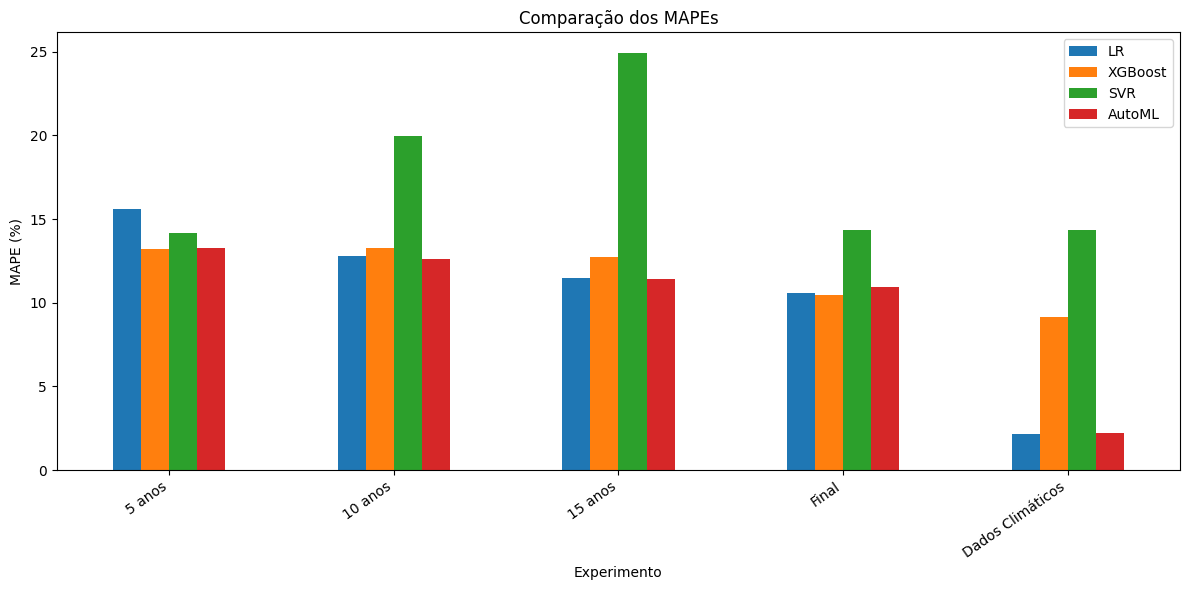

In [40]:
# Gráfico de comparação dos MAPE
import matplotlib.pyplot as plt

comparacao_plot = comparacao_geral.set_index("Experimento")[["LR", "XGBoost", "SVR", "AutoML"]]
comparacao_plot.plot(kind="bar", figsize=(12, 6))
plt.ylabel("MAPE (%)")
plt.title("Comparação dos MAPEs")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


##  Modelos selecionados pela FLAML e hiperparâmetros

In [41]:
infos_automl = {
    "5 anos": info_automl_5,
    "10 anos": info_automl_10,
    "15 anos": info_automl_15,
    "Final": info_automl_final,
    "Dados Climáticos": info_automl_clima
}

linhas = []

for experimento, info in infos_automl.items():
    for pais, modelo in info["modelos"].items():
        linhas.append({
            "Experimento": experimento,
            "País": pais,
            "Modelo selecionado": modelo
        })

modelos_selecionados = pd.DataFrame(linhas)

print("Frequência dos modelos selecionados:")
display(
    modelos_selecionados
    .groupby(["Experimento", "Modelo selecionado"])
    .size()
    .reset_index(name="Quantidade")
)

pais_exemplo = "Brazil"
print("\nExemplo - Brazil:")
print("Modelo:", info_automl_final["modelos"][pais_exemplo])
print("Hiperparâmetros:", info_automl_final["hiperparametros"][pais_exemplo])


Frequência dos modelos selecionados:


,Experimento,Modelo selecionado,Quantidade
0,10 anos,enet,9
1,10 anos,lgbm,1
2,10 anos,rf,1
3,10 anos,xgboost,1
4,15 anos,enet,9
5,15 anos,rf,3
6,5 anos,enet,7
7,5 anos,lgbm,2
8,5 anos,rf,2
9,5 anos,xgboost,1



Exemplo - Brazil:
Modelo: enet
Hiperparâmetros: {'alpha': 1.0, 'l1_ratio': np.float64(0.38622283906962585), 'selection': np.str_('random')}


## Custo computacional

,Experimento,Regressão Linear,XGBoost,SVR,AutoML
0,5 anos,0.14,0.83,0.28,30.36
1,10 anos,0.14,0.88,0.27,12.90
2,15 anos,0.14,0.93,0.27,12.37
3,Final,0.08,0.53,0.16,12.25
4,Dados Climáticos,0.01,0.36,0.03,11.31


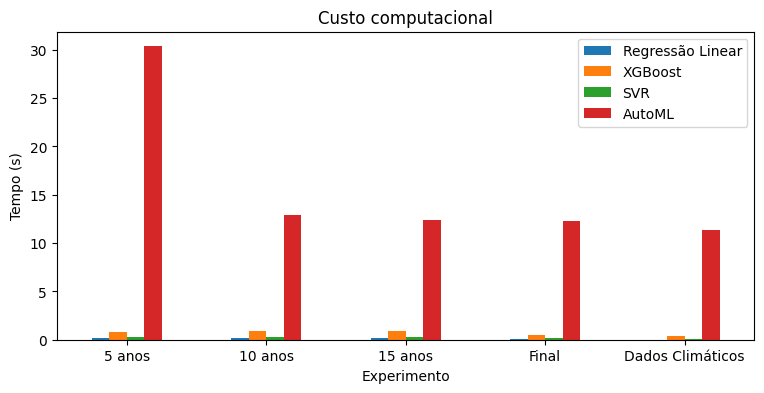

In [42]:
# Mede separadamente o custo dos modelos originais
import io
import contextlib
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

def medir_modelos_originais(caminho_notebook, indices):
    tempos = {
        "Regressão Linear": 0.0,
        "XGBoost": 0.0,
        "SVR": 0.0
    }

    metodos_originais = {
        "lr_fit": LinearRegression.fit,
        "lr_predict": LinearRegression.predict,
        "xgb_fit": XGBRegressor.fit,
        "xgb_predict": XGBRegressor.predict,
        "svr_fit": SVR.fit,
        "svr_predict": SVR.predict,
        "scaler_fit": StandardScaler.fit,
        "scaler_transform": StandardScaler.transform
    }

    def medir(funcao, modelo):
        def wrapper(self, *args, **kwargs):
            inicio = time.perf_counter()
            resultado = funcao(self, *args, **kwargs)
            tempos[modelo] += time.perf_counter() - inicio
            return resultado
        return wrapper

    LinearRegression.fit = medir(metodos_originais["lr_fit"], "Regressão Linear")
    LinearRegression.predict = medir(metodos_originais["lr_predict"], "Regressão Linear")

    XGBRegressor.fit = medir(metodos_originais["xgb_fit"], "XGBoost")
    XGBRegressor.predict = medir(metodos_originais["xgb_predict"], "XGBoost")

    SVR.fit = medir(metodos_originais["svr_fit"], "SVR")
    SVR.predict = medir(metodos_originais["svr_predict"], "SVR")

    # A normalização faz parte do processamento usado pelo SVR original
    StandardScaler.fit = medir(metodos_originais["scaler_fit"], "SVR")
    StandardScaler.transform = medir(metodos_originais["scaler_transform"], "SVR")

    try:
        with open(caminho_notebook, "r", encoding="utf-8") as arquivo:
            notebook = json.load(arquivo)

        ambiente = {
            "__builtins__": __builtins__,
            "display": lambda *args, **kwargs: None
        }

        with contextlib.redirect_stdout(io.StringIO()):
            for indice in indices:
                celula = notebook["cells"][indice]
                if celula.get("cell_type") == "code":
                    codigo = "".join(celula.get("source", []))
                    exec(codigo, ambiente)

    finally:
        LinearRegression.fit = metodos_originais["lr_fit"]
        LinearRegression.predict = metodos_originais["lr_predict"]

        XGBRegressor.fit = metodos_originais["xgb_fit"]
        XGBRegressor.predict = metodos_originais["xgb_predict"]

        SVR.fit = metodos_originais["svr_fit"]
        SVR.predict = metodos_originais["svr_predict"]

        StandardScaler.fit = metodos_originais["scaler_fit"]
        StandardScaler.transform = metodos_originais["scaler_transform"]

    return tempos


tempos_5 = medir_modelos_originais(
    Path("/content/mlarrozprevisao") / r"Experimentos_Preliminares/Treinamento_Rice_South_America_2014_a_2018_5anos.ipynb",
    [1, 2, 3]
)

tempos_10 = medir_modelos_originais(
    Path("/content/mlarrozprevisao") / r"Experimentos_Preliminares/Treinamento_Rice_South_America_2009_a_2018_5anos.ipynb",
    [1, 2, 3]
)

tempos_15 = medir_modelos_originais(
    Path("/content/mlarrozprevisao") / r"Experimentos_Preliminares/Treinamento_Rice_South_America_2004_a_2018_5anos.ipynb",
    [1, 2, 3]
)

tempos_final = medir_modelos_originais(
    Path("/content/mlarrozprevisao") / r"Treinamento_Rice_South_America_2011_a_2020_3anos.ipynb",
    [1, 2, 3]
)

tempos_clima = medir_modelos_originais(
    Path("/content/mlarrozprevisao") / r"Treinamento_Rice_NASA_Clima_South_America_2011_a_2020_3anos.ipynb",
    [1, 2, 3]
)


custos_modelos = pd.DataFrame([
    {
        "Experimento": "5 anos",
        **tempos_5,
        "AutoML": info_automl_5["tempo_segundos"]
    },
    {
        "Experimento": "10 anos",
        **tempos_10,
        "AutoML": info_automl_10["tempo_segundos"]
    },
    {
        "Experimento": "15 anos",
        **tempos_15,
        "AutoML": info_automl_15["tempo_segundos"]
    },
    {
        "Experimento": "Final",
        **tempos_final,
        "AutoML": info_automl_final["tempo_segundos"]
    },
    {
        "Experimento": "Dados Climáticos",
        **tempos_clima,
        "AutoML": info_automl_clima["tempo_segundos"]
    }
])

display(custos_modelos.round(2))

custos_modelos.plot(
    x="Experimento",
    kind="bar",
    figsize=(9, 4)
)

plt.ylabel("Tempo (s)")
plt.title("Custo computacional")
plt.xticks(rotation=0)
plt.show()
